In [ ]:
!pip install opencv-python matplotlib numpy pandas pillow

In [ ]:
!pip install deepface

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 36.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.5/69.5 MB 36.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [deepface]


In [1]:
from pathlib import Path
import os

working_dir = Path.cwd().resolve()
project_candidates = [working_dir, working_dir / "repository", *working_dir.parents]
PROJECT_ROOT = next(
    path for path in project_candidates
    if (path / "data" / "raw" / "image_recordings_dataset" / "Images").is_dir()
)
dataset_path = PROJECT_ROOT / "data" / "raw" / "image_recordings_dataset"
image_root = dataset_path / "Images"
output_folder = PROJECT_ROOT / "data" / "processed"
augmented_folder = output_folder / "augmented_images"
augmented_folder.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print("Members:", sorted(path.name for path in image_root.iterdir() if path.is_dir()))

Project root: /Users/nives/ALU/ML_pipeline/repository
Members: ['Bridget', 'Merci', 'Yves']


In [ ]:
for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if level >= 3:
        dirs[:] = []

Image and recordings dataset/
    Images/
        Merci/
            Surprised.jpeg
            Smiling.jpeg
            Neutral.jpeg
        Bridget/
            Neutral.jpeg
            Smiling.jpeg
            Surprised.jpeg
        Yves/
            Neutral.jpeg
            Surprised.jpeg
            Smiling.jpeg
    Recordings/
        Merci Recording/
            Merci_transaction.mp3
            Merci_approve.mp3
        Bridget Recording/
            Bridget_transaction.mp3
            Bridget_approve.mp3
        Yves Recording/
            Yves_approve.mp3
            Yves_transaction.mp3
    Outputs/
        failed_images.csv
        image_features.csv
        sample_image_augmentations.png
        Augmented_Images/
            Neutral_rotated.jpeg
            Neutral_grayscale.jpeg
            Neutral_flipped.jpeg
            Smiling_flipped.jpeg
            Smiling_rotated.jpeg
            Bridget/
                Neutral_flipped.jpeg
                Smiling_grayscale.jpeg


In [2]:
# Identify all people from the repository's original image folder.
people = sorted(
    folder for folder in os.listdir(image_root)
    if os.path.isdir(os.path.join(image_root, folder))
)
print("People found:", people)

People found: ['Bridget', 'Merci', 'Yves']


In [3]:
from PIL import Image
import matplotlib.pyplot as plt

image_extensions = (".jpg", ".jpeg", ".png")

all_images = []

for person in sorted(people):

    person_folder = os.path.join(image_root, person)

    for filename in sorted(os.listdir(person_folder)):

        if filename.lower().endswith(image_extensions):

            image_path = os.path.join(person_folder, filename)

            img = Image.open(image_path).convert("RGB")

            all_images.append({
                "person": person,
                "filename": filename,
                "path": image_path,
                "image": img
            })

print("Total original images:", len(all_images))

Total original images: 9


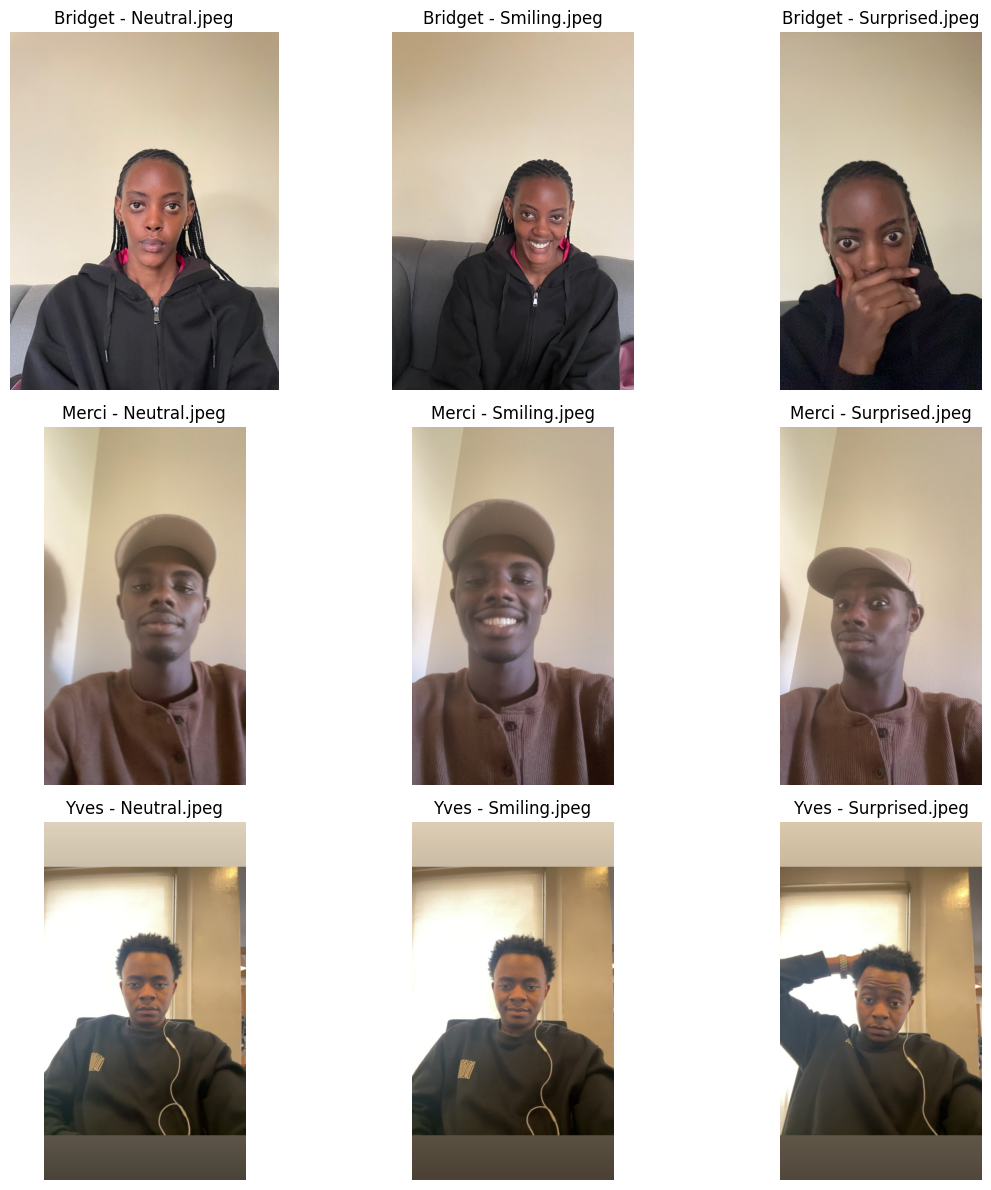

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for ax, item in zip(axes.flatten(), all_images):

    ax.imshow(item["image"])
    ax.set_title(f'{item["person"]} - {item["filename"]}')
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import ImageOps

for item in all_images:

    person = item["person"]
    filename = item["filename"]
    img = item["image"]

    # Create a separate folder for each person
    person_output = os.path.join(augmented_folder, person)
    os.makedirs(person_output, exist_ok=True)

    # Generate augmentations
    rotated = img.rotate(10)
    flipped = ImageOps.mirror(img)
    grayscale = ImageOps.grayscale(img)

    # Get filename without extension
    name = os.path.splitext(filename)[0]

    # Save augmented images
    rotated.save(os.path.join(
        person_output, f"{name}_rotated.jpeg"
    ))

    flipped.save(os.path.join(
        person_output, f"{name}_flipped.jpeg"
    ))

    grayscale.save(os.path.join(
        person_output, f"{name}_grayscale.jpeg"
    ))

print("Augmentation completed!")

Augmentation completed!


In [ ]:
from PIL import Image, ImageOps
import os

# Reuse the repository paths initialized in the first setup cell.
images_folder = image_root
augmented_folder = output_folder / "augmented_images"
augmented_folder.mkdir(parents=True, exist_ok=True)

members = sorted(
    folder for folder in os.listdir(images_folder)
    if os.path.isdir(os.path.join(images_folder, folder))
)
print("Members found:", members)

total_original = 0
total_augmented = 0

for member in members:
    member_folder = os.path.join(images_folder, member)
    member_output = os.path.join(augmented_folder, member)
    os.makedirs(member_output, exist_ok=True)
    image_files = sorted(
        file for file in os.listdir(member_folder)
        if file.lower().endswith((".jpeg", ".jpg", ".png"))
    )

    print(f"\nProcessing images for {member}...")
    for name in image_files:
        image_path = os.path.join(member_folder, name)
        image = Image.open(image_path).convert("RGB")
        filename = os.path.splitext(name)[0]
        variants = {
            "rotated": image.rotate(10),
            "flipped": ImageOps.mirror(image),
            "grayscale": ImageOps.grayscale(image),
        }
        for suffix, variant in variants.items():
            variant.save(os.path.join(member_output, f"{filename}_{suffix}.jpeg"))
        total_original += 1
        total_augmented += len(variants)
        print(f"  Completed: {name}")

print("\nImage augmentation completed!")
print("Total original images:", total_original)
print("Total augmented images:", total_augmented)

Members found: ['Merci', 'Bridget', 'Yves']

Processing images for Merci...
  Completed: Surprised.jpeg
  Completed: Smiling.jpeg
  Completed: Neutral.jpeg

Processing images for Bridget...
  Completed: Neutral.jpeg
  Completed: Smiling.jpeg
  Completed: Surprised.jpeg

Processing images for Yves...
  Completed: Neutral.jpeg
  Completed: Surprised.jpeg
  Completed: Smiling.jpeg

Image augmentation completed!
Total original images: 9
Total augmented images: 27


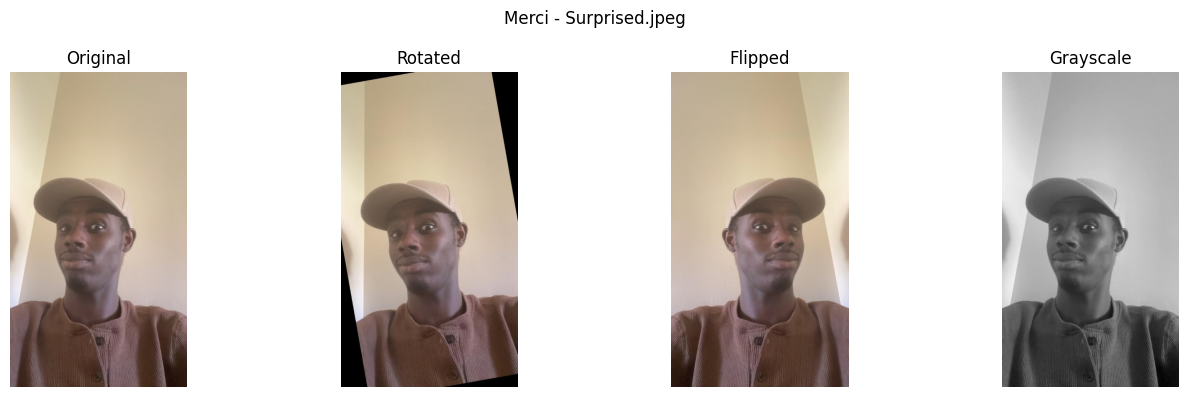

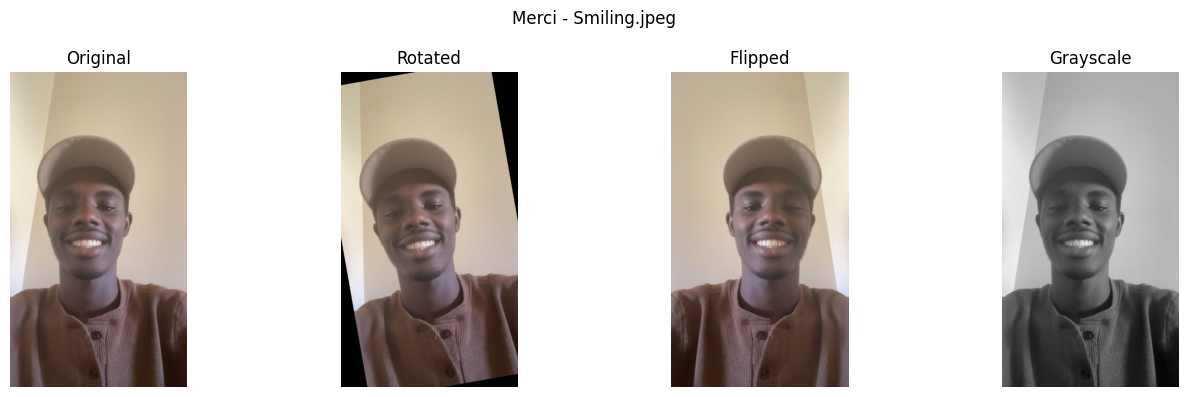

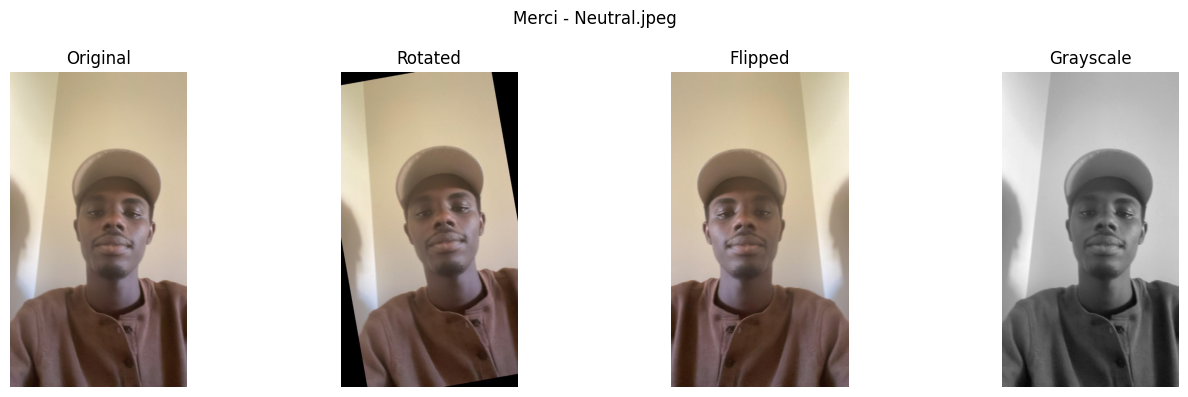

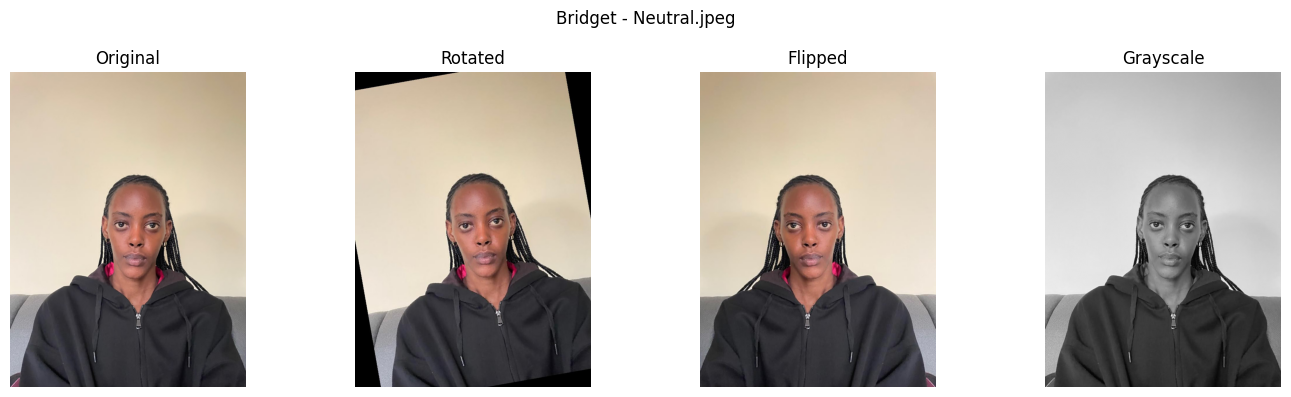

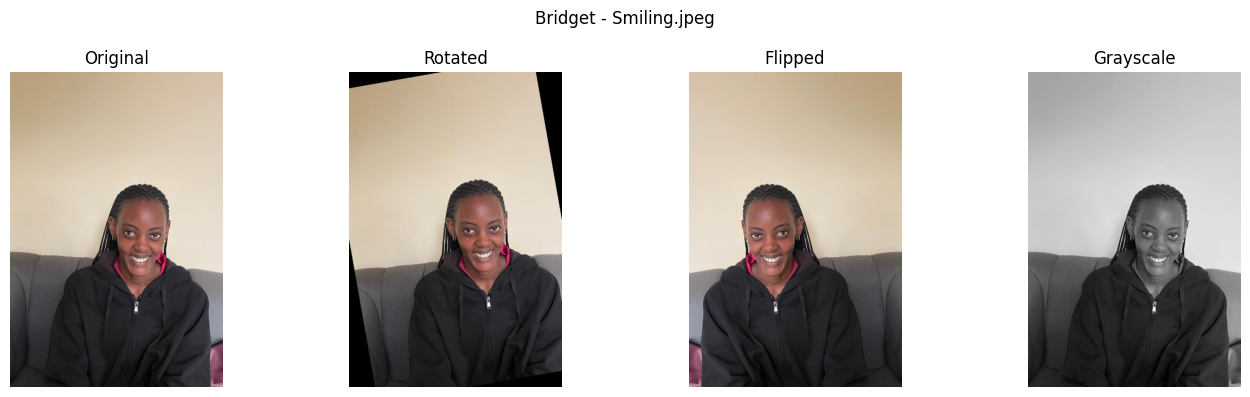

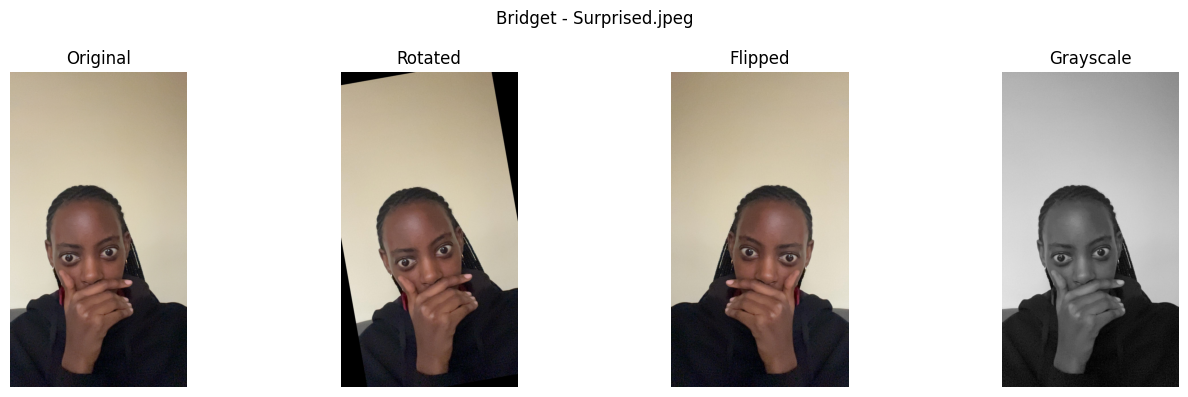

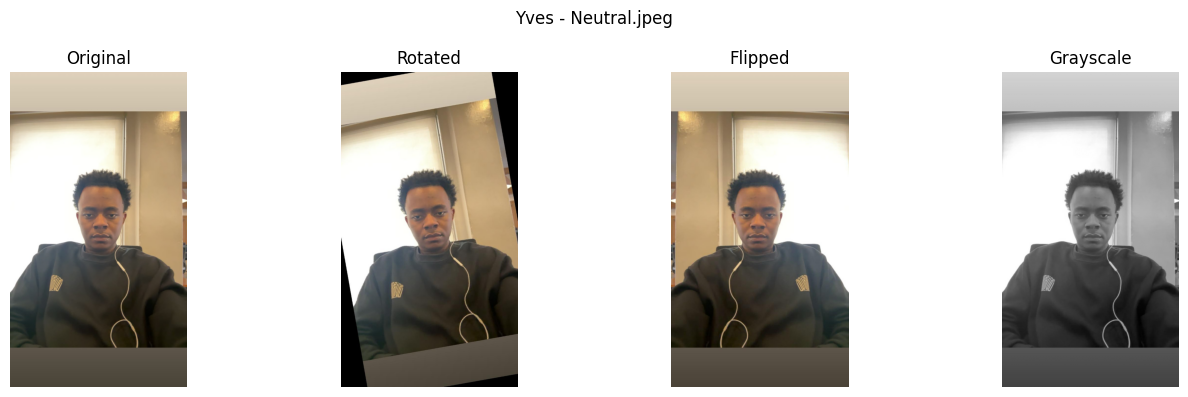

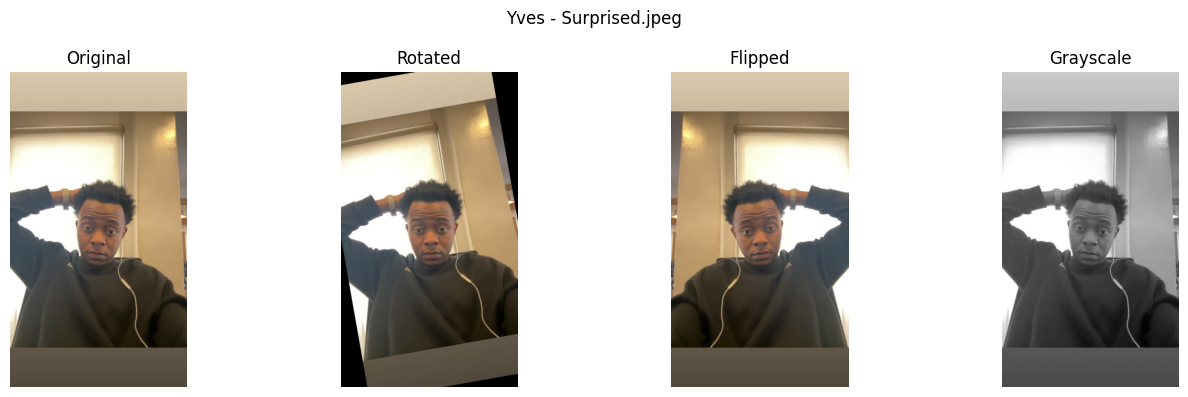

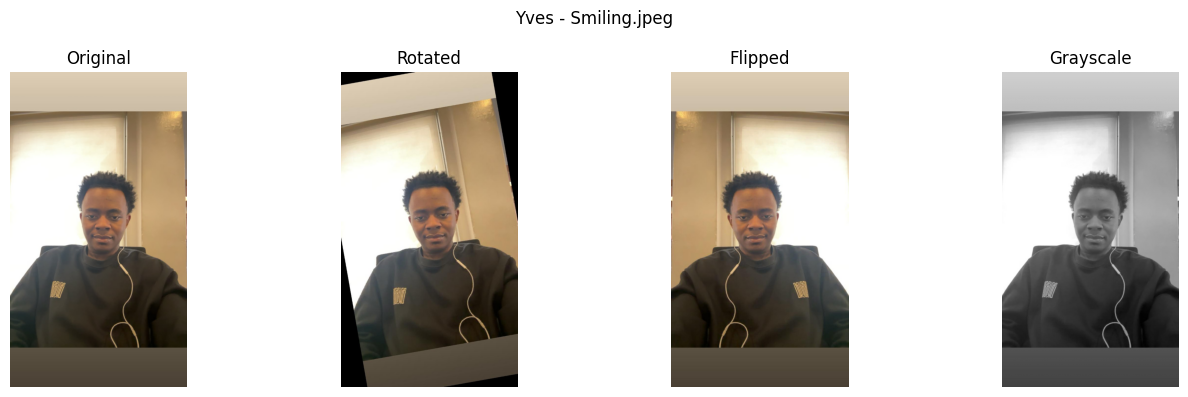

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
import os

for member in members:

    member_folder = os.path.join(images_folder, member)
    member_output = os.path.join(augmented_folder, member)

    image_files = [
        f for f in os.listdir(member_folder)
        if f.lower().endswith((".jpeg", ".jpg", ".png"))
    ]

    for name in image_files:

        filename = os.path.splitext(name)[0]

        paths = [
            os.path.join(member_folder, name),
            os.path.join(member_output, f"{filename}_rotated.jpeg"),
            os.path.join(member_output, f"{filename}_flipped.jpeg"),
            os.path.join(member_output, f"{filename}_grayscale.jpeg")
        ]

        titles = ["Original", "Rotated", "Flipped", "Grayscale"]

        fig, axes = plt.subplots(1, 4, figsize=(14, 4))

        for ax, path, title in zip(axes, paths, titles):

            img = Image.open(path)

            ax.imshow(
                img,
                cmap="gray" if title == "Grayscale" else None
            )

            ax.set_title(title)
            ax.axis("off")

        plt.suptitle(f"{member} - {name}")
        plt.tight_layout()
        plt.show()


In [ ]:
!pip install deepface

In [4]:
from deepface import DeepFace
import pandas as pd
import os

print("DeepFace imported successfully!")

/Users/nives/ALU/ML_pipeline/.venv-1/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


DeepFace imported successfully!


In [5]:
smiling_path = image_root / "Merci" / "Smiling.jpeg"
print(smiling_path)

/Users/nives/ALU/ML_pipeline/repository/data/raw/image_recordings_dataset/Images/Merci/Smiling.jpeg


testing whether face detection works before processing the entire dataset!

In [6]:
from deepface import DeepFace

result = DeepFace.represent(
    img_path=smiling_path,
    model_name="Facenet512",
    detector_backend="retinaface",
    enforce_detection=True
)

print("Face detected successfully!")
print("Number of features:", len(result[0]["embedding"]))

Face detected successfully!
Number of features: 512


In [7]:
import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageOps, ImageEnhance
from deepface import DeepFace

image_features_path = output_folder / "image_features.csv"

def generate_augmentations(pil_img):
    """Apply deterministic rotation, flip, grayscale, and brightness augmentations."""
    return {
        "original": pil_img,
        "rotated": pil_img.rotate(15, resample=Image.BICUBIC, fillcolor=(128, 128, 128)),
        "flipped": ImageOps.mirror(pil_img),
        "grayscale": ImageOps.grayscale(pil_img).convert("RGB"),
        "brightness": ImageEnhance.Brightness(pil_img).enhance(1.2),
    }

def extract_rgb_histogram(pil_img, bins=16):
    """Extract normalized 16-bin RGB color histograms (48 values)."""
    pixels = np.asarray(pil_img)
    features = {}
    for channel_index, channel_name in enumerate(("r", "g", "b")):
        histogram = cv2.calcHist([pixels], [channel_index], None, [bins], [0, 256]).flatten()
        histogram = histogram / (histogram.sum() + 1e-7)
        for bin_index, value in enumerate(histogram):
            features[f"hist_{channel_name}_{bin_index}"] = float(value)
    return features

def extract_embedding(pil_img):
    """Extract an L2-normalized 512-D Facenet512 embedding."""
    image_bgr = cv2.cvtColor(np.asarray(pil_img), cv2.COLOR_RGB2BGR)
    try:
        representation = DeepFace.represent(
            img_path=image_bgr,
            model_name="Facenet512",
            detector_backend="retinaface",
            enforce_detection=True,
        )
    except Exception:
        representation = DeepFace.represent(
            img_path=image_bgr,
            model_name="Facenet512",
            detector_backend="skip",
            enforce_detection=False,
        )
    embedding = np.asarray(representation[0]["embedding"], dtype=np.float32)
    embedding = embedding / (np.linalg.norm(embedding) + 1e-8)
    return {f"emb_{index}": float(value) for index, value in enumerate(embedding)}

feature_rows = []
for item in all_images:
    person = item["person"]
    filename = item["filename"]
    expression = os.path.splitext(filename)[0].lower()
    base_image = item["image"].resize((224, 224))
    member_output = augmented_folder / person
    member_output.mkdir(parents=True, exist_ok=True)

    for augmentation, augmented_image in generate_augmentations(base_image).items():
        if augmentation != "original":
            augmented_image.save(member_output / f"{expression}_{augmentation}.jpeg")
        row = {
            "person": person,
            "expression": expression,
            "augmentation": augmentation,
            "source_file": filename,
        }
        row.update(extract_rgb_histogram(augmented_image, bins=16))
        row.update(extract_embedding(augmented_image))
        feature_rows.append(row)

image_features_df = pd.DataFrame(feature_rows)
image_features_path.parent.mkdir(parents=True, exist_ok=True)
image_features_df.to_csv(image_features_path, index=False)

expected_columns = {*(f"hist_{channel}_{index}" for channel in "rgb" for index in range(16)), *(f"emb_{index}" for index in range(512))}
assert expected_columns.issubset(image_features_df.columns)
print("Image feature table shape:", image_features_df.shape)
print("Saved image features:", image_features_path.relative_to(PROJECT_ROOT))
display(image_features_df.iloc[:, :10].head())

Image feature table shape: (45, 564)
Saved image features: data/processed/image_features.csv


,person,expression,augmentation,source_file,hist_r_0,hist_r_1,hist_r_2,hist_r_3,hist_r_4,hist_r_5
0,Bridget,neutral,original,Neutral.jpeg,0.005780,0.019531,0.108418,0.134945,0.022282,0.006876
1,Bridget,neutral,rotated,Neutral.jpeg,0.005481,0.019013,0.097258,0.119719,0.016761,0.006597
2,Bridget,neutral,flipped,Neutral.jpeg,0.005780,0.019531,0.108418,0.134945,0.022282,0.006876
3,Bridget,neutral,grayscale,Neutral.jpeg,0.005879,0.019711,0.107980,0.139967,0.024992,0.012058
4,Bridget,neutral,brightness,Neutral.jpeg,0.004145,0.010961,0.038604,0.140605,0.082071,0.014569


\If we want to visualise everything that was produced by our